# 02 · Construction des variables

L'idée est d'ajouter des variables qu'un arbre retrouve mal tout seul avec des seuils, sans toucher aux 56 colonnes d'origine. Aucune n'utilise la cible.

Trois séries :

1. bornes numériques du DTI, LTV recalculé, ratios de revenu, profil de valeurs manquantes, fréquences géographiques ;
2. précision de saisie du LTV, seuils de LTV selon le type de prêt, valeur du bien reconstituée, durée ;
3. idées venues de l'analyse des résidus (notebook 05) : indicateurs de produit, cohérence du LTV, cumul de risques, revenu relatif au secteur.

Chaque série est testée par **ablation**, avec un CatBoost rapide et les cinq plis fixes. On garde un bloc si le gain moyen d'AUC atteint le seuil et s'il est positif sur au moins 4 plis sur 5. Toutes les variables sont enregistrées dans `artifacts/02_feature_engineering/feature_store/` pour les notebooks suivants.

Les cinq notebooks : 01 données → 02 variables → 03 choix des modèles → 04 modèle final → 05 analyse des erreurs. Les CSV sont dans `data/`, les résultats dans `artifacts/<nom du notebook>/`.

In [1]:
# Environnement, chemins et fonctions partagés par les cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import shutil
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def find_project_dir():
    candidates = []
    if os.environ.get('HMDA_PROJECT_DIR'):
        candidates.append(Path(os.environ['HMDA_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir HMDA_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                                        # CSV sources (lecture seule)
ARTIFACTS = PROJECT_DIR / 'artifacts'                                  # Résultats dans un sous-dossier par notebook
PREPARED_DIR = ARTIFACTS / '01_data_exploration'                       # 01 : données préparées et schéma fixe
FEATURE_DIR = ARTIFACTS / '02_feature_engineering' / 'feature_store'   # 02 : feature store
SEED = 42
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})


def ensure_catboost():
    """Installe et importe la version fixée de CatBoost pour le réentraînement."""
    global catboost
    try:
        installed = importlib.metadata.version('catboost')
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != CATBOOST_VERSION:
        if 'catboost' in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà chargée ; redémarrer puis relancer le notebook')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', f'catboost=={CATBOOST_VERSION}'])
        importlib.invalidate_caches()
    import catboost as catboost_module
    if catboost_module.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version chargée : {catboost_module.__version__}')
    catboost = catboost_module
    return catboost_module


def ensure_gpu():
    """Vérifie la présence du GPU NVIDIA avant le réentraînement."""
    global GPU_NAME
    if shutil.which('nvidia-smi') is None:
        raise RuntimeError('GPU requis : choisir un GPU T4 dans le type de session Colab, puis relancer')
    probe = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           text=True, capture_output=True, check=False)
    if probe.returncode != 0 or not probe.stdout.strip():
        raise RuntimeError('GPU NVIDIA indisponible : choisir un T4 puis relancer')
    GPU_NAME = probe.stdout.strip().splitlines()[0]
    return GPU_NAME


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')

Projet : demandes-de-pret-immobilier-aux-etats-unis
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3


In [2]:
"""Identifiants de stockage historiques et libellés descriptifs.

Les valeurs assurent la reprise exacte des artefacts existants. Les paramètres,
les features et leur ordre sont définis dans les cellules métier.
Cette cellule est intégrée à chaque notebook : aucun import local requis.
"""

MODEL_DEPTH6_INITIAL = 'M0_C11_all'
MODEL_DEPTH6_ENRICHED = 'M1_C11_G7'
MODEL_DEPTH8_ENRICHED = 'M2_C7_G7'
MODEL_DEPTH6_REDUCED = 'M3_C11_lean'
FEATURE_SET_INITIAL = 'ROUND1_ALL'
FEATURE_SET_ENRICHED = 'G7'
FEATURE_SET_REDUCED = 'LEAN'
ENSEMBLE_THREE_MODELS_SEED42 = 'B13_seed42'
ENSEMBLE_MULTISEED = 'B_seeds'
ENSEMBLE_MULTISEED_PREFIX = 'B_seeds_'
ENSEMBLE_FULL_MULTISEED = 'full_Bseeds'
MODEL_INITIAL_POOL_LABEL = 'M0'
LEARNING_CURVE_SUBSET = 'LC_sub80'
LEARNING_CURVE_FULL = 'LC_full'
REDUCED_MODEL_CV_AUC = 'M3_in_13'
BASELINE_CATBOOST_DEPTH6 = 'CatBoost_R1'
BASELINE_CATBOOST_DEPTH8 = 'CatBoost_R2'
LIGHTGBM_LEAVES31 = 'L1_lgbm_leaves31'
LIGHTGBM_LEAVES127 = 'L2_lgbm_leaves127'
OBSERVED_LABELS_ONLY = 'A_base'
SOFT_PSEUDO_LABELS = 'A_pseudo'
LEARNING_CURVE_RUN_PATTERN = 'LC_*__fold?.json'
LEARNING_CURVE_FULL_PATTERN = 'LC_full__fold?.json'
REDUCED_MODEL_RUN_PATTERN = 'M3_C11_lean__fold?.json'
LIGHTGBM_RUN_PATTERN = 'L*_lgbm_*__fold?.json'
PSEUDO_LABEL_RUN_PATTERN = 'A_*__fold?.json'
FULL_ENSEMBLE_SUBMISSION = 'submission_full_Bseeds.csv'
ABLATION_ORIGINAL = 'F0_base'
ABLATION_ADD_DTI = 'F1_dti'
ABLATION_ADD_LTV = 'F2_ltv'
ABLATION_ADD_INCOME = 'F3_income'
ABLATION_ADD_MISSINGNESS = 'F4_missing'
ABLATION_ADD_GEOGRAPHIC_COUNTS = 'F5_freq'
ABLATION_INITIAL = 'F6_all'
ABLATION_INITIAL_REFERENCE = 'G0_all'
ABLATION_ADD_LTV_PRECISION = 'G1_precision'
ABLATION_ADD_LTV_THRESHOLDS = 'G2_thresholds'
ABLATION_ADD_IMPLIED_VALUE = 'G3_implied'
ABLATION_ADD_TERM = 'G4_term'
ABLATION_ENRICHED_WITH_COUNTS = 'G5_round2_all'
ABLATION_CORE_WITHOUT_COUNTS = 'G6_nofreq'
ABLATION_ENRICHED = 'G7_nofreq_round2_all'
ABLATION_ENRICHED_REFERENCE = 'H0_G7'
ABLATION_ADD_PRODUCT_FLAGS = 'H1_purpose'
ABLATION_ADD_LTV_CONSISTENCY = 'H2_ltv_consistency'
ABLATION_ADD_RISK_INTERACTIONS = 'H3_risk_layers'
ABLATION_ADD_TRACT_INCOME = 'H4_tract_income'
ABLATION_ALL_PRODUCT_RISK = 'H5_round3_all'
TUNING_DEPTH8_FIXED1600 = 'B0_R2_fixed1600'
TUNING_DEPTH8_LR005_L2_3 = 'C1_d8_lr05_l2_3_es'
TUNING_DEPTH6_LR003_L2_10 = 'C6_d6_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_10 = 'C3_d8_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_3 = 'C2_d8_lr03_l2_3'
TUNING_DEPTH8_LR003_L2_30 = 'C4_d8_lr03_l2_30'
TUNING_DEPTH8_BERNOULLI80 = 'C7_d8_lr03_l2_10_sub80'
TUNING_DEPTH8_WITH_DTI = 'C8_d8_lr03_l2_10_DTI'
TUNING_DEPTH10_LR003_L2_10 = 'C5_d10_lr03_l2_10'
TUNING_DEPTH8_LR002_L2_10 = 'C9_d8_lr02_l2_10'
TUNING_DEPTH8_L2_30_BERNOULLI80 = 'C10_d8_lr03_l2_30_sub80'
TUNING_DEPTH6_BERNOULLI80 = 'C11_d6_lr03_l2_10_sub80'
TRAINING_STANDARD = 'V0_base'
TRAINING_ORDERED = 'V1_ordered'
TRAINING_NEWTON_SCORE = 'V2_newtonL2'
TRAINING_DEPTHWISE = 'V3_depthwise'
TRAINING_LOSSGUIDE = 'V4_lossguide'
TRAINING_POISSON = 'V5_poisson'
TRAINING_ROWS066 = 'V6_sub066'
TRAINING_BINS254 = 'V7_border254'
TRAINING_NO_CATEGORY_COMBINATIONS = 'V8_ctr1'
TRAINING_DROP_REDUNDANT_DEMOGRAPHICS = 'V9_drop_demo'
MEAN_GAIN_VS_SOURCE_FEATURES = 'mean_delta_vs_F0'
FOLDS_BETTER_THAN_SOURCE_FEATURES = 'folds_better_than_F0'
MEAN_GAIN_VS_INITIAL_FEATURES = 'mean_delta_vs_G0'
FOLDS_BETTER_THAN_INITIAL_FEATURES = 'folds_better_than_G0'
MEAN_GAIN_VS_ENRICHED_FEATURES = 'mean_delta_vs_H0'
FOLDS_BETTER_THAN_ENRICHED_FEATURES = 'folds_better_than_H0'
MEAN_GAIN_VS_FIXED_ITERATIONS = 'mean_delta_vs_B0'
FOLDS_BETTER_THAN_FIXED_ITERATIONS = 'folds_better_than_B0'
MEAN_GAIN_VS_STANDARD_BOOSTING = 'mean_delta_vs_V0'
FOLDS_BETTER_THAN_STANDARD_BOOSTING = 'folds_better_than_V0'
GAIN_VS_THREE_MODEL_ENSEMBLE = 'delta_vs_B13'
FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE = 'folds_better_than_B13'
TABM_ENSEMBLE_SUBMISSION_PREFIX = 'submission_Bseeds_TabM_w'
PURPOSE_ABLATION = 'feature block ablation, fast GPU CatBoost, paired vs F0_base'
PURPOSE_TRAINING_MODES = 'data-efficiency screen on M3 features; inner 15% early stop, score probe model on outer fold'
PURPOSE_TABM = 'TabM-mini (PyTorch) on G7 features; inner 15% early stop, no outer refit'
PURPOSE_FULL_REFIT = 'learning curve (80% vs 100% of outer-train) + full-data refit of M1-M3 x 3 seeds'

DISPLAY_LABELS = {
    MODEL_DEPTH6_INITIAL: 'CatBoost profondeur 6 · variables initiales',
    MODEL_DEPTH6_ENRICHED: 'CatBoost profondeur 6 · variables enrichies',
    MODEL_DEPTH8_ENRICHED: 'CatBoost profondeur 8 · variables enrichies',
    MODEL_DEPTH6_REDUCED: 'CatBoost profondeur 6 · variables réduites',
    FEATURE_SET_INITIAL: 'Variables initiales (68 colonnes)',
    FEATURE_SET_ENRICHED: 'Variables enrichies (72 colonnes)',
    FEATURE_SET_REDUCED: 'Variables réduites (68 colonnes)',
    ENSEMBLE_THREE_MODELS_SEED42: 'Ensemble de trois modèles · graine 42',
    ENSEMBLE_MULTISEED: 'Ensemble de trois modèles et trois graines',
    ENSEMBLE_MULTISEED_PREFIX: 'Ensemble multigraines · ',
    ENSEMBLE_FULL_MULTISEED: 'Ensemble multigraines sur toutes les données',
    MODEL_INITIAL_POOL_LABEL: 'CatBoost profondeur 6 · variables initiales',
    LEARNING_CURVE_SUBSET: 'Apprentissage sur 67 200 lignes',
    LEARNING_CURVE_FULL: 'Apprentissage sur 84 000 lignes',
    REDUCED_MODEL_CV_AUC: 'AUC du modèle réduit en validation croisée',
    BASELINE_CATBOOST_DEPTH6: 'CatBoost profondeur 6',
    BASELINE_CATBOOST_DEPTH8: 'CatBoost profondeur 8',
    LIGHTGBM_LEAVES31: 'LightGBM · 31 feuilles',
    LIGHTGBM_LEAVES127: 'LightGBM · 127 feuilles',
    OBSERVED_LABELS_ONLY: 'Cibles observées uniquement',
    SOFT_PSEUDO_LABELS: 'Pseudo-étiquettes souples',
    LEARNING_CURVE_RUN_PATTERN: 'Courbe d’apprentissage',
    LEARNING_CURVE_FULL_PATTERN: 'Courbe sur 84 000 lignes',
    REDUCED_MODEL_RUN_PATTERN: 'Validation croisée du modèle réduit',
    LIGHTGBM_RUN_PATTERN: 'Modèles LightGBM',
    PSEUDO_LABEL_RUN_PATTERN: 'Comparaison des pseudo-étiquettes',
    FULL_ENSEMBLE_SUBMISSION: 'Soumission de l’ensemble complet',
    ABLATION_ORIGINAL: 'Variables sources',
    ABLATION_ADD_DTI: 'Ajout des bornes DTI',
    ABLATION_ADD_LTV: 'Ajout de la cohérence LTV',
    ABLATION_ADD_INCOME: 'Ajout des ratios de revenu',
    ABLATION_ADD_MISSINGNESS: 'Ajout des valeurs manquantes',
    ABLATION_ADD_GEOGRAPHIC_COUNTS: 'Ajout des fréquences géographiques',
    ABLATION_INITIAL: 'Toutes les variables initiales',
    ABLATION_INITIAL_REFERENCE: 'Référence : variables initiales',
    ABLATION_ADD_LTV_PRECISION: 'Ajout de la précision LTV',
    ABLATION_ADD_LTV_THRESHOLDS: 'Ajout des seuils LTV',
    ABLATION_ADD_IMPLIED_VALUE: 'Ajout de la valeur immobilière implicite',
    ABLATION_ADD_TERM: 'Ajout des variables de durée',
    ABLATION_ENRICHED_WITH_COUNTS: 'Variables enrichies avec fréquences géographiques',
    ABLATION_CORE_WITHOUT_COUNTS: 'Variables initiales sans fréquences géographiques',
    ABLATION_ENRICHED: 'Variables enrichies sans fréquences géographiques',
    ABLATION_ENRICHED_REFERENCE: 'Référence : variables enrichies',
    ABLATION_ADD_PRODUCT_FLAGS: 'Ajout des indicateurs de produit',
    ABLATION_ADD_LTV_CONSISTENCY: 'Ajout de la cohérence des intervalles LTV',
    ABLATION_ADD_RISK_INTERACTIONS: 'Ajout des interactions de risque',
    ABLATION_ADD_TRACT_INCOME: 'Ajout du revenu relatif au secteur',
    ABLATION_ALL_PRODUCT_RISK: 'Ajout de tous les blocs produit et risque',
    TUNING_DEPTH8_FIXED1600: 'Profondeur 8 · 1 600 itérations fixes',
    TUNING_DEPTH8_LR005_L2_3: 'Profondeur 8 · taux 0.05 · L2=3',
    TUNING_DEPTH6_LR003_L2_10: 'Profondeur 6 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_10: 'Profondeur 8 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_3: 'Profondeur 8 · taux 0.03 · L2=3',
    TUNING_DEPTH8_LR003_L2_30: 'Profondeur 8 · taux 0.03 · L2=30',
    TUNING_DEPTH8_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TUNING_DEPTH8_WITH_DTI: 'Profondeur 8 · taux 0.03 · L2=10 · bornes DTI',
    TUNING_DEPTH10_LR003_L2_10: 'Profondeur 10 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR002_L2_10: 'Profondeur 8 · taux 0.02 · L2=10',
    TUNING_DEPTH8_L2_30_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=30 · Bernoulli 0.8',
    TUNING_DEPTH6_BERNOULLI80: 'Profondeur 6 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TRAINING_STANDARD: 'Boosting standard',
    TRAINING_ORDERED: 'Boosting ordonné',
    TRAINING_NEWTON_SCORE: 'Score NewtonL2',
    TRAINING_DEPTHWISE: 'Croissance par profondeur',
    TRAINING_LOSSGUIDE: 'Croissance guidée par la perte',
    TRAINING_POISSON: 'Échantillonnage Poisson',
    TRAINING_ROWS066: 'Échantillonnage des lignes à 0.66',
    TRAINING_BINS254: '254 seuils numériques',
    TRAINING_NO_CATEGORY_COMBINATIONS: 'Sans combinaison de catégories',
    TRAINING_DROP_REDUNDANT_DEMOGRAPHICS: 'Sans colonnes démographiques redondantes',
    MEAN_GAIN_VS_SOURCE_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_SOURCE_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_INITIAL_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_INITIAL_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_ENRICHED_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_ENRICHED_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_FIXED_ITERATIONS: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_FIXED_ITERATIONS: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_STANDARD_BOOSTING: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_STANDARD_BOOSTING: 'Plis meilleurs que la référence',
    GAIN_VS_THREE_MODEL_ENSEMBLE: 'Gain face à l’ensemble de trois modèles',
    FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE: 'Plis meilleurs que l’ensemble de trois modèles',
    TABM_ENSEMBLE_SUBMISSION_PREFIX: 'submission_Bseeds_TabM_w',
}

def semantic_label(value):
    """Décrit un identifiant historique pour l’affichage uniquement."""
    if not isinstance(value, str):
        return value
    # Un chemin affiché doit continuer à désigner le fichier réellement présent.
    if value.endswith(('.csv', '.json', '.parquet', '.npy')):
        return value
    if value in DISPLAY_LABELS:
        return DISPLAY_LABELS[value]
    for stored in sorted(DISPLAY_LABELS, key=len, reverse=True):
        value = value.replace(stored, DISPLAY_LABELS[stored])
    return value


def display_named(value, *args, **kwargs):
    """Affiche une copie : index, colonnes et libellés lisibles, calculs inchangés."""
    if isinstance(value, (pd.DataFrame, pd.Series)):
        value = value.copy(deep=True)
        if not isinstance(value.index, pd.MultiIndex):
            value.index = value.index.map(semantic_label)
        if isinstance(value, pd.DataFrame):
            value.columns = value.columns.map(semantic_label)
            for column in value.select_dtypes(include=['object', 'string']).columns:
                value[column] = value[column].map(semantic_label)
        elif value.dtype == object:
            value = value.map(semantic_label)
    display(value, *args, **kwargs)

**Entraînement.** Tous les boutons de `TRAIN` sont à `False` : les notebooks relisent les résultats sauvegardés dans `artifacts/`. Deux exceptions : le notebook 01 entraîne un petit modèle de contrôle sur CPU et le notebook 02 réécrit les variables. Pour refaire une expérience, mettre son bouton à `True` et choisir un **GPU T4** si le bloc le demande. Les modèles déjà entraînés sont sauvegardés et ne sont pas refaits.

In [3]:
TRAIN = {
    'ablation_round1': False,   # Série 1 : 7 variantes × 5 folds, environ 70 min
    'ablation_round2': False,   # Série 2 : 8 variantes × 5 folds, environ 80 min
    'ablation_round3': False,   # Série 3 : 6 variantes × 5 folds, environ 60 min
}

## 1. Chargement des données préparées

Vérification des fichiers du notebook 01 : empreintes, ordre des colonnes, identifiants, plis.

In [4]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


manifest_path = PREPARED_DIR / 'manifest.json'
schema_path = PREPARED_DIR / 'schema.json'
if not manifest_path.is_file() or not schema_path.is_file():
    raise FileNotFoundError(
        f'Fichier manquant : {manifest_path} ou {schema_path} ; exécuter d’abord 01_data_exploration.ipynb'
    )
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
schema = json.loads(schema_path.read_text(encoding='utf-8'))
require(manifest['schema_version'] == schema['schema_version'] == '1.0', 'Version du contrat de données incompatible')
require(manifest['seed'] == SEED and manifest['n_splits'] == 5, 'Configuration des cinq folds incompatible')
require(set(manifest['source_files']) == {'train.csv', 'test.csv', 'sample_submission.csv'},
        'Liste des fichiers source incomplète')
expected_prepared = {
    'train_features.csv', 'test_features.csv', 'train_labels.csv',
    'test_ids.csv', 'folds.csv', 'audit.csv', 'schema.json',
}
require(set(manifest['output_files']) == expected_prepared, 'Liste des fichiers préparés incomplète')
for name, info in manifest['source_files'].items():
    path = DATA_DIR / name
    require(path.is_file(), f'Données source manquantes : {path}')
    require(sha256_file(path) == info['sha256'], f'Fichier source modifié : {name} ; réexécuter 01')
for name, info in manifest['output_files'].items():
    path = PREPARED_DIR / name
    require(path.is_file(), f'Fichier préparé manquant : {path}')
    require(sha256_file(path) == info['sha256'], f'Empreinte du fichier préparé différente : {name} ; réexécuter 01')

FEATURE_COLUMNS = schema['feature_columns']
NUMERIC_COLUMNS = schema['numeric_columns']
CATEGORICAL_COLUMNS = schema['categorical_columns']
require(len(FEATURE_COLUMNS) == 56 and len(NUMERIC_COLUMNS) == 13
        and len(CATEGORICAL_COLUMNS) == 43, '56 colonnes attendues : 13 numériques, 43 catégorielles')
require(set(FEATURE_COLUMNS) == set(NUMERIC_COLUMNS + CATEGORICAL_COLUMNS),
        'Répartition numérique/catégorielle incomplète')
require(not {'id', 'accepted'} & set(FEATURE_COLUMNS), 'Les ID et la cible ne peuvent pas servir de variables')


def read_features(path):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    require(frame.columns.tolist() == FEATURE_COLUMNS, f'Variables ou ordre des colonnes incompatibles : {path.name}')
    for column in NUMERIC_COLUMNS:
        frame[column] = pd.to_numeric(
            frame[column].replace('', np.nan), errors='raise',
        ).astype('float64')
    require(not np.isinf(frame[NUMERIC_COLUMNS].to_numpy()).any(), 'Valeurs infinies dans les colonnes numériques')
    require(not frame[CATEGORICAL_COLUMNS].eq('').any().any(), 'Chaînes vides dans les colonnes catégorielles')
    return frame


X_base = read_features(PREPARED_DIR / 'train_features.csv')
X_test_base = read_features(PREPARED_DIR / 'test_features.csv')
labels = pd.read_csv(PREPARED_DIR / 'train_labels.csv', dtype=str, keep_default_na=False)
test_id_frame = pd.read_csv(PREPARED_DIR / 'test_ids.csv', dtype=str, keep_default_na=False)
fold_frame = pd.read_csv(PREPARED_DIR / 'folds.csv', dtype=str, keep_default_na=False)
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype=str, keep_default_na=False)

require(labels.columns.tolist() == ['id', 'accepted'], 'Colonnes des cibles train incompatibles')
require(test_id_frame.columns.tolist() == ['id'], 'Colonnes des ID test incompatibles')
require(fold_frame.columns.tolist() == ['id', 'fold'], 'Colonnes du fichier de folds incompatibles')
require(sample_submission.columns.tolist() == ['id', 'accepted'], 'Colonnes du modèle de soumission incompatibles')
require(len(X_base) == len(labels) == len(fold_frame) == 105000, 'Nombre de lignes train incorrect')
require(len(X_test_base) == len(test_id_frame) == len(sample_submission) == 45000,
        'Nombre de lignes test incorrect')

train_ids = labels['id']
test_ids = test_id_frame['id']
require(train_ids.is_unique and test_ids.is_unique, 'ID en double')
require(train_ids.ne('').all() and test_ids.ne('').all(), 'ID vide')
require(train_ids.equals(fold_frame['id']), 'ID des folds désalignés avec le train')
require(test_ids.equals(sample_submission['id']), 'Ordre des ID test différent du modèle de soumission')
require(set(train_ids).isdisjoint(test_ids), 'ID communs au train et au test')
require(set(labels['accepted']) == {'0', '1'}, 'accepted doit contenir les deux valeurs 0 et 1')
raw_train_identity = pd.read_csv(
    DATA_DIR / 'train.csv', usecols=['id', 'accepted'],
    dtype=str, keep_default_na=False,
)
raw_test_identity = pd.read_csv(
    DATA_DIR / 'test.csv', usecols=['id'], dtype=str, keep_default_na=False,
)
require(train_ids.equals(raw_train_identity['id'])
        and labels['accepted'].equals(raw_train_identity['accepted']),
        'ID ou cibles préparés différents du train.csv initial')
require(test_ids.equals(raw_test_identity['id']),
        'ID test préparés différents du test.csv initial')
y = labels['accepted'].astype('int8')
require(set(fold_frame['fold']) == {'1', '2', '3', '4', '5'}, 'Les folds doivent être numérotés de 1 à 5')
fold_assignment = fold_frame['fold'].astype('int8').to_numpy()

expected_folds = np.zeros(len(X_base), dtype=np.int8)
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (_, valid_index) in enumerate(splitter.split(X_base, y), start=1):
    expected_folds[valid_index] = fold
require(np.array_equal(fold_assignment, expected_folds), 'Les folds ne correspondent pas au découpage fixe avec seed=42')
DATA_HASHES = {
    'manifest.json': sha256_file(manifest_path),
    **{name: info['sha256'] for name, info in manifest['output_files'].items()},
}
print(f'Données vérifiées : train {len(X_base):,}, test {len(X_test_base):,}, 56 variables initiales.')
display_named(pd.crosstab(fold_assignment, y, rownames=['fold'], colnames=['accepted']))

def checked_probabilities(model, features):
    require(list(model.classes_) == [0, 1], 'Ordre des classes différent de [0, 1]')
    probability = np.asarray(model.predict_proba(features)[:, 1], dtype=float)
    require(probability.ndim == 1 and len(probability) == len(features)
            and np.isfinite(probability).all()
            and ((probability >= 0) & (probability <= 1)).all(),
            'Probabilités prédites invalides')
    return probability


def write_json(path, payload):
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')
    tmp.replace(path)


def fixed_config(output_dir, config):
    """Écrire la configuration au premier passage, puis exiger son identité pour ne pas mélanger les expériences."""
    output_dir.mkdir(parents=True, exist_ok=True)
    path = output_dir / 'config.json'
    if path.is_file():
        saved = json.loads(path.read_text(encoding='utf-8'))
        require(saved == config,
                f'{output_dir.name} contient des résultats avec une autre configuration ; changer EXPERIMENT_ID')
    else:
        write_json(path, config)

Données vérifiées : train 105,000, test 45,000, 56 variables initiales.


accepted,0,1
fold,,
1,3151,17849
2,3151,17849
3,3151,17849
4,3151,17849
5,3152,17848


## 2. Première série

### Bornes du DTI

Le DTI est donné par intervalles (`30%-<36%`). On en tire deux colonnes numériques, la borne basse et la borne haute, en gardant la catégorie d'origine. Une borne inconnue reste `NaN`.

In [5]:
DTI_BOUNDS = {
    **{str(value): (float(value), float(value)) for value in range(36, 50)},
    '20%-<30%': (20.0, 30.0),
    '30%-<36%': (30.0, 36.0),
    '50%-60%': (50.0, 60.0),
    '<20%': (np.nan, 20.0),
    '>60%': (60.0, np.nan),
    'MISSING': (np.nan, np.nan),
}


def add_dti_bounds(frame):
    unknown = set(frame['debt_to_income_ratio'].unique()) - set(DTI_BOUNDS)
    require(not unknown, f'Catégories DTI inconnues : {sorted(map(str, unknown))}')
    result = frame.copy()
    pairs = frame['debt_to_income_ratio'].map(DTI_BOUNDS)
    result['dti_lower'] = pairs.map(lambda pair: pair[0]).astype('float64')
    result['dti_upper'] = pairs.map(lambda pair: pair[1]).astype('float64')
    require(result.columns.tolist() == FEATURE_COLUMNS + ['dti_lower', 'dti_upper'],
            'Colonnes DTI ou ordre incorrects')
    require(result['debt_to_income_ratio'].equals(frame['debt_to_income_ratio']),
            'Les catégories DTI initiales ont été modifiées')
    return result


X_dti = add_dti_bounds(X_base)
X_test_dti = add_dti_bounds(X_test_base)
print(f'Variables candidates : 56 colonnes initiales + 2 bornes DTI = {X_dti.shape[1]} colonnes.')
display_named(X_dti[['debt_to_income_ratio', 'dti_lower', 'dti_upper']].head())

Variables candidates : 56 colonnes initiales + 2 bornes DTI = 58 colonnes.


,debt_to_income_ratio,dti_lower,dti_upper
0,20%-<30%,20.0,30.0
1,49,49.0,49.0
2,20%-<30%,20.0,30.0
3,44,44.0,44.0
4,<20%,NaN,20.0


### Les blocs

Un ratio n'est calculé que si son dénominateur est strictement positif ; sinon il est manquant.

| Bloc | Colonnes | Idée |
|---|---|---|
| `dti` | `dti_lower`, `dti_upper` | bornes numériques du DTI |
| `ltv` | `ltv_calc`, `ltv_gap` | LTV recalculé (prêt / valeur du bien) et écart avec le LTV déclaré |
| `income` | `income_to_area`, `loan_to_income`, `value_to_income` | revenu par rapport à la zone ; prêt et valeur du bien par rapport au revenu |
| `missing` | `missing_pattern`, `missing_count` | quels champs manquent, et combien |
| `freq` | `freq_county_code`, `freq_derived_msa-md`, `freq_state_code` | fréquence du comté, de l'aire urbaine et de l'État dans apprentissage + test |

In [6]:
def safe_ratio(numerator, denominator):
    valid = numerator.notna() & denominator.notna() & (denominator > 0)
    return (numerator / denominator.where(valid)).where(valid).astype('float64')


def build_blocks(train, test):
    both = pd.concat([train, test], ignore_index=True)
    blocks = {}
    blocks['dti'] = add_dti_bounds(both)[['dti_lower', 'dti_upper']]

    ltv_calc = 100 * safe_ratio(both['loan_amount'], both['property_value'])
    blocks['ltv'] = pd.DataFrame({
        'ltv_calc': ltv_calc,
        'ltv_gap': both['loan_to_value_ratio'] - ltv_calc,
    })

    income_dollars = both['income'] * 1000      # Les revenus HMDA sont exprimés en milliers de dollars
    blocks['income'] = pd.DataFrame({
        'income_to_area': safe_ratio(income_dollars, both['ffiec_msa_md_median_family_income']),
        'loan_to_income': safe_ratio(both['loan_amount'], income_dollars),
        'value_to_income': safe_ratio(both['property_value'], income_dollars),
    })

    missing = pd.DataFrame({
        'ltv': both['loan_to_value_ratio'].isna(),
        'pv': both['property_value'].isna(),
        'inc': both['income'].isna(),
        'term': both['loan_term'].isna(),
        'dti': both['debt_to_income_ratio'].eq('MISSING'),
        'age': both['applicant_age'].eq('MISSING'),
    })
    blocks['missing'] = pd.DataFrame({
        'missing_pattern': 'm' + missing.astype(int).astype(str).agg(''.join, axis=1),
        'missing_count': missing.sum(axis=1).astype('float64'),
    })

    freq = {}
    for column in ['county_code', 'derived_msa-md', 'state_code']:
        counts = both[column].map(both[column].value_counts()).astype('float64')
        freq[f'freq_{column}'] = counts.where(both[column].ne('MISSING'))
    blocks['freq'] = pd.DataFrame(freq)

    n_train = len(train)
    out = {}
    for name, frame in blocks.items():
        require(len(frame) == len(both), f'{name} : nombre de lignes incorrect')
        out[name] = (frame.iloc[:n_train].reset_index(drop=True),
                     frame.iloc[n_train:].reset_index(drop=True))
    return out


BLOCKS = build_blocks(X_base, X_test_base)
NEW_CATEGORICAL = {'missing_pattern'}


def variant_frames(blocks):
    train_parts = [X_base] + [BLOCKS[b][0] for b in blocks]
    test_parts = [X_test_base] + [BLOCKS[b][1] for b in blocks]
    train = pd.concat(train_parts, axis=1)
    test = pd.concat(test_parts, axis=1)
    require(train.columns.is_unique and train.columns.equals(test.columns), 'Colonnes incohérentes entre variantes')
    require(train.iloc[:, :len(FEATURE_COLUMNS)].equals(X_base), 'Les 56 colonnes initiales ont été modifiées')
    cats = CATEGORICAL_COLUMNS + [c for c in train.columns if c in NEW_CATEGORICAL]
    return train, test, cats


for name, (train_block, _) in BLOCKS.items():
    described = train_block.describe(include='all').T
    print(f'\n[{name}] Taux de valeurs manquantes : ', train_block.isna().mean().round(3).to_dict())
    display_named(described.iloc[:, :6])


[dti] Taux de valeurs manquantes :  {'dti_lower': 0.117, 'dti_upper': 0.117}


,count,mean,std,min,25%,50%
dti_lower,92671.0,39.680947,10.654997,20.0,30.0,42.0
dti_upper,92730.0,41.033290,9.699260,20.0,36.0,40.0



[ltv] Taux de valeurs manquantes :  {'ltv_calc': 0.045, 'ltv_gap': 0.118}


,count,mean,std,min,25%,50%
ltv_calc,100244.0,82.070292,54.826068,0.302115,74.683544,88.235294
ltv_gap,92643.0,5.568211,439.329812,-7717.790000,-0.719136,0.000000



[income] Taux de valeurs manquantes :  {'income_to_area': 0.054, 'loan_to_income': 0.053, 'value_to_income': 0.088}


,count,mean,std,min,25%,50%
income_to_area,99343.0,1.563771,3.274112,-6.550349,0.746269,1.108830
loan_to_income,99468.0,2.891506,4.565102,0.002606,1.810560,2.692308
value_to_income,95792.0,3.713296,6.426108,0.009722,2.378641,3.288576



[missing] Taux de valeurs manquantes :  {'missing_pattern': 0.0, 'missing_count': 0.0}


,count,unique,top,freq,mean,std
missing_pattern,105000.0,42.0,m000000,88200.0,NaN,NaN
missing_count,105000.0,NaN,NaN,NaN,0.336019,0.956439



[freq] Taux de valeurs manquantes :  {'freq_county_code': 0.013, 'freq_derived_msa-md': 0.0, 'freq_state_code': 0.008}


,count,mean,std,min,25%,50%
freq_county_code,103661.0,364.801787,470.338073,1.0,67.0,200.0
freq_derived_msa-md,105000.0,4000.393038,7326.553843,2.0,353.0,927.0
freq_state_code,104176.0,6209.485976,4859.097575,2.0,2667.0,4441.0


## 3. Deuxième série

`ltv_precision` regarde le **texte** du LTV dans le CSV (`80.0` ou `79.85`), d'où la relecture de cette colonne en chaîne.

| Bloc | Colonnes | Pourquoi |
|---|---|---|
| `precision` | `ltv_precision` (absent, entier, 1 à 3 décimales, plus) | 90.7 % d'acceptation pour un LTV entier contre 84.4 % avec deux décimales : la façon de déclarer dépend sans doute de l'établissement |
| `thresholds` | `ltv_band`, `ltv_over_program` | position par rapport à 80, 95, 97 et 100 ; écart au plafond habituel du type de prêt (classique 97, FHA 96.5, VA et RHS 100) |
| `implied` | `implied_property_value`, `implied_value_ratio` | valeur du bien déduite du prêt et du LTV, comparée à la valeur déclarée |
| `term` | `term_is_360`, `term_years` | durée en années, indicateur de prêt sur 30 ans |

In [7]:
def read_raw_ltv(path):
    text = pd.read_csv(path, usecols=['loan_to_value_ratio'], dtype=str,
                       keep_default_na=False)['loan_to_value_ratio']
    return text


raw_ltv = pd.concat([read_raw_ltv(PREPARED_DIR / 'train_features.csv'),
                     read_raw_ltv(PREPARED_DIR / 'test_features.csv')], ignore_index=True)
both = pd.concat([X_base, X_test_base], ignore_index=True)
require(len(raw_ltv) == len(both), 'Nombre de lignes du LTV texte incorrect')
require(pd.to_numeric(raw_ltv.replace('', np.nan)).equals(both['loan_to_value_ratio'])
        or np.allclose(pd.to_numeric(raw_ltv.replace('', np.nan)), both['loan_to_value_ratio'],
                       equal_nan=True), 'LTV texte et numérique incohérents')

decimals = raw_ltv.str.split('.').str[1].fillna('')
precision = np.select(
    [raw_ltv.eq(''), decimals.isin(['', '0']), decimals.str.len().eq(1),
     decimals.str.len().eq(2), decimals.str.len().eq(3)],
    ['missing', 'integer', 'dec1', 'dec2', 'dec3'], default='dec4plus',
)
ltv = both['loan_to_value_ratio']
band = np.select(
    [ltv.isna(), ltv < 80, ltv == 80, ltv < 95, ltv < 97, ltv < 100, ltv == 100],
    ['missing', 'lt80', 'eq80', '80_95', '95_97', '97_100', 'eq100'], default='gt100',
)
PROGRAM_MAX_LTV = {'1': 97.0, '2': 96.5, '3': 100.0, '4': 100.0}   # Conventionnel / FHA / VA / RHS
unknown_types = set(both['loan_type']) - set(PROGRAM_MAX_LTV)
require(not unknown_types, f'Valeurs loan_type inconnues : {sorted(unknown_types)}')
implied_value = safe_ratio(both['loan_amount'] * 100, ltv)
term = both['loan_term']

round2 = {
    'precision': pd.DataFrame({'ltv_precision': precision}),
    'thresholds': pd.DataFrame({
        'ltv_band': band,
        'ltv_over_program': ltv - both['loan_type'].map(PROGRAM_MAX_LTV).astype('float64'),
    }),
    'implied': pd.DataFrame({
        'implied_property_value': implied_value,
        'implied_value_ratio': safe_ratio(implied_value, both['property_value']),
    }),
    'term': pd.DataFrame({
        'term_is_360': term.eq(360).astype('float64').where(term.notna()),
        'term_years': (term / 12).round(1),
    }),
}
n_train = len(X_base)
for name, frame in round2.items():
    require(len(frame) == len(both), f'{name} : nombre de lignes incorrect')
    BLOCKS[name] = (frame.iloc[:n_train].reset_index(drop=True),
                    frame.iloc[n_train:].reset_index(drop=True))
NEW_CATEGORICAL |= {'ltv_precision', 'ltv_band'}

train_labels_check = y.to_numpy()
for column, frame in [('ltv_precision', round2['precision']), ('ltv_band', round2['thresholds'])]:
    table = pd.crosstab(frame[column].iloc[:n_train], train_labels_check, normalize='index')
    counts = frame[column].iloc[:n_train].value_counts()
    display_named(table.assign(rows=counts).round(3))
for name in ['implied', 'term']:
    display_named(BLOCKS[name][0].describe().T.round(3))
del both

col_0,0,1,rows
ltv_precision,,,
dec1,0.125,0.875,12131
dec2,0.156,0.844,9717
dec3,0.125,0.875,19531
dec4plus,0.154,0.846,306
integer,0.093,0.907,51441
missing,0.462,0.538,11874


col_0,0,1,rows
ltv_band,,,
80_95,0.122,0.878,14329
95_97,0.117,0.883,20177
97_100,0.129,0.871,6015
eq100,0.107,0.893,7295
eq80,0.081,0.919,13455
gt100,0.176,0.824,5711
lt80,0.096,0.904,26144
missing,0.462,0.538,11874


,count,mean,std,min,25%,50%,75%,max
implied_property_value,93126.0,526207.615,2740245.581,0.011,243523.316,367875.648,554999.602,6.270987e+08
implied_value_ratio,92643.0,1.051,2.960,0.003,0.989,1.000,1.009,1.108650e+02


,count,mean,std,min,25%,50%,75%,max
term_is_360,101693.0,0.841,0.366,0.0,1.0,1.0,1.0,1.0
term_years,101693.0,28.146,5.534,0.1,30.0,30.0,30.0,40.0


## 4. Troisième série

| Bloc | Colonnes | Pourquoi |
|---|---|---|
| `purpose` | `product_flags` | sept indicateurs de produit regroupés ; c'est là que les résidus étaient les plus dispersés |
| `ltv_consistency` | `ltv_consistency`, `ltv_outside_interval` | le LTV déclaré est-il compatible avec des montants arrondis à 10 000 dollars ? |
| `risk_layers` | `risk_layer_count`, `risk_layer_pattern` | cumul de facteurs : LTV ou DTI élevé, pas de système automatisé, résidence non principale, LTV absent, second rang |
| `tract_income` | `income_to_tract` | revenu par rapport à la médiane du secteur de recensement |

In [8]:
both = pd.concat([X_base, X_test_base], ignore_index=True)
ltv = both['loan_to_value_ratio']
loan, value = both['loan_amount'], both['property_value']

# Dans les données publiques HMDA, montant et valeur immobilière sont les milieux de tranches de 10 000 $ (terminaison 5000 dans le train).
# Le LTV calculé définit donc un intervalle ; un LTV déclaré hors intervalle suggère une base de valorisation différente.
require(((loan % 10000) == 5000).all(), 'Certains montants ne sont pas des milieux de tranches de 10 000 $ ; hypothèse invalide')
ltv_min = 100 * safe_ratio(loan - 5000, value + 5000)
ltv_max = 100 * safe_ratio(loan + 5000, value - 5000)
outside = np.where(ltv.isna() | ltv_min.isna(), np.nan,
                   np.where(ltv < ltv_min, ltv - ltv_min, np.where(ltv > ltv_max, ltv - ltv_max, 0.0)))
consistency = np.select([ltv.isna() | ltv_min.isna(), outside == 0, outside < 0],
                        ['unknown', 'inside', 'below'], default='above')

PRODUCT_FLAGS = ['business_or_commercial_purpose', 'open-end_line_of_credit', 'reverse_mortgage',
                 'interest_only_payment', 'balloon_payment', 'negative_amortization',
                 'other_nonamortizing_features']
purpose = both[PRODUCT_FLAGS].astype(str).agg('|'.join, axis=1)

dti_lower = add_dti_bounds(both)['dti_lower']
risk = pd.DataFrame({
    'high_ltv': ltv > 95,
    'high_dti': dti_lower >= 45,                 # DTI élevé certain seulement si la borne basse ≥ 45
    'no_aus': both['aus-1'].eq('6'),             # aus-1 = 6 : aucun système de décision automatisée
    'not_owner_occupied': both['occupancy_type'].ne('1'),
    'ltv_missing': ltv.isna(),
    'second_lien': both['lien_status'].eq('2'),
})
tract_median_income = both['ffiec_msa_md_median_family_income'] * both['tract_to_msa_income_percentage'] / 100

round3 = {
    'purpose': pd.DataFrame({'product_flags': 'p' + purpose}),
    'ltv_consistency': pd.DataFrame({'ltv_consistency': consistency,
                                     'ltv_outside_interval': outside}),
    'risk_layers': pd.DataFrame({'risk_layer_count': risk.sum(axis=1).astype('float64'),
                                 'risk_layer_pattern': 'r' + risk.astype(int).astype(str).agg(''.join, axis=1)}),
    'tract_income': pd.DataFrame({'income_to_tract': safe_ratio(both['income'] * 1000, tract_median_income)}),
}
n_train = len(X_base)
for name, frame in round3.items():
    require(len(frame) == len(both), f'{name} : nombre de lignes incorrect')
    BLOCKS[name] = (frame.iloc[:n_train].reset_index(drop=True),
                    frame.iloc[n_train:].reset_index(drop=True))
NEW_CATEGORICAL |= {'product_flags', 'ltv_consistency', 'risk_layer_pattern'}

for column, block in [('product_flags', 'purpose'), ('ltv_consistency', 'ltv_consistency'),
                      ('risk_layer_count', 'risk_layers')]:
    values = BLOCKS[block][0][column]
    table = pd.crosstab(values, y.to_numpy(), normalize='index').assign(rows=values.value_counts())
    display_named(table.sort_values('rows', ascending=False).head(10).round(3))
display_named(BLOCKS['tract_income'][0].describe().T.round(3))
del both

col_0,0,1,rows
product_flags,,,
p2|2|2|2|2|2|2,0.147,0.853,91062
p1|2|2|2|2|2|2,0.149,0.851,4355
p1111|1111|1111|1111|1111|1111|1111,0.086,0.914,2955
p2|2|2|1|2|2|2,0.245,0.755,1491
p1|2|2|1|1|2|2,0.172,0.828,1449
p2|2|2|2|1|2|2,0.091,0.909,866
p2|1|2|1|2|2|2,0.323,0.677,734
p2|1|2|2|2|2|2,0.512,0.488,582
p1|2|2|2|1|2|2,0.059,0.941,460


col_0,0,1,rows
ltv_consistency,,,
inside,0.102,0.898,80904
unknown,0.468,0.532,12357
above,0.141,0.859,8211
below,0.153,0.847,3528


col_0,0,1,rows
risk_layer_count,,,
1.0,0.107,0.893,38980
0.0,0.040,0.960,31319
2.0,0.229,0.771,26814
3.0,0.561,0.439,7074
4.0,0.306,0.694,808
5.0,0.200,0.800,5


,count,mean,std,min,25%,50%,75%,max
income_to_tract,98063.0,1.471,3.178,-5.798,0.754,1.092,1.623,717.462


## 5. Enregistrement des variables

Les notebooks 03 à 05 relisent ces fichiers et vérifient leurs empreintes. Cette cellule écrit les fichiers même si tous les boutons `TRAIN` sont à `False`.

In [9]:
# Sauvegarde les colonnes ajoutées ; les 56 colonnes sources restent fournies par 01.
FEATURE_SETS = {
    FEATURE_SET_INITIAL: ['dti', 'ltv', 'income', 'missing', 'freq'],                                   # Tous les blocs de la série 1 (68 colonnes)
    FEATURE_SET_ENRICHED: ['dti', 'ltv', 'income', 'missing', 'precision', 'thresholds', 'implied', 'term'],      # les deux modèles enrichis finaux (72 colonnes)
    FEATURE_SET_REDUCED: ['dti', 'ltv', 'income', 'missing', 'precision', 'thresholds'],                      # CatBoost profondeur 6 réduit final (68 colonnes)
}
block_columns = {name: list(train_block.columns) for name, (train_block, _) in BLOCKS.items()}
all_columns = [c for columns in block_columns.values() for c in columns]
require(len(all_columns) == len(set(all_columns)), 'Noms de colonnes dupliqués entre blocs')
train_store = pd.concat([BLOCKS[name][0] for name in block_columns], axis=1)
test_store = pd.concat([BLOCKS[name][1] for name in block_columns], axis=1)
require(train_store.shape == (len(X_base), len(all_columns))
        and test_store.shape == (len(X_test_base), len(all_columns)), 'Dimensions du feature store incorrectes')
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
store_paths = {'train': FEATURE_DIR / 'blocks_train.parquet', 'test': FEATURE_DIR / 'blocks_test.parquet'}
train_store.to_parquet(store_paths['train'], index=False)
test_store.to_parquet(store_paths['test'], index=False)
write_json(FEATURE_DIR / 'feature_store.json', {
    'blocks': block_columns,
    'categorical': sorted(c for c in NEW_CATEGORICAL if c in all_columns),
    'feature_sets': FEATURE_SETS,
    'rows': {'train': len(train_store), 'test': len(test_store)},
    'data_hashes': DATA_HASHES,
    'files': {path.name: sha256_file(path) for path in store_paths.values()},
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
})
for part, frame in [('train', train_store), ('test', test_store)]:
    restored = pd.read_parquet(store_paths[part])
    pd.testing.assert_frame_equal(restored.reset_index(drop=True), frame.reset_index(drop=True), check_dtype=False)
display_named(pd.DataFrame([{'Bloc': name, 'Nombre de colonnes': len(cols), 'Colonnes': ', '.join(cols)} for name, cols in block_columns.items()]))
print(f'Variables enregistrées dans {FEATURE_DIR.relative_to(PROJECT_DIR)} : {len(all_columns)} colonnes, relecture vérifiée.')

,Bloc,Nombre de colonnes,Colonnes
0,dti,2,"dti_lower, dti_upper"
1,ltv,2,"ltv_calc, ltv_gap"
2,income,3,"income_to_area, loan_to_income, value_to_income"
3,missing,2,"missing_pattern, missing_count"
4,freq,3,"freq_county_code, freq_derived_msa-md, freq_st..."
5,precision,1,ltv_precision
6,thresholds,2,"ltv_band, ltv_over_program"
7,implied,2,"implied_property_value, implied_value_ratio"
8,term,2,"term_is_360, term_years"
9,purpose,1,product_flags


Variables enregistrées dans artifacts/02_feature_engineering/feature_store : 25 colonnes, relecture vérifiée.


## 6. Ablations

**Modèle rapide** : CatBoost sur GPU, profondeur 8, taux d'apprentissage 0.05, L2 = 3, Bernoulli 0.8, 1 600 itérations. Chaque variante ajoute un ou plusieurs blocs à la référence. Dans les tableaux, `delta_vs_base` est le gain moyen, `folds_better` le nombre de plis améliorés, `keep` indique si le critère est rempli.

In [10]:
# Lit les résultats JSON par modèle et fold pour des comparaisons appariées.
def load_runs(directory, pattern='*__fold?.json'):
    directory = Path(directory)
    paths = sorted(directory.glob(pattern))
    require(paths, f'Aucun résultat dans {directory} : synchroniser artifacts depuis Drive ou activer le réentraînement')
    return pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in paths])


def paired_table(runs, key, baseline, min_gain=0.0005, min_folds=4):
    auc = runs.pivot(index='fold', columns=key, values='valid_auc')
    require(baseline in auc.columns, f'Référence absente : {baseline}')
    delta = auc.sub(auc[baseline], axis=0)
    table = pd.DataFrame({
        'folds': auc.notna().sum(),
        'mean_auc': auc.mean(),
        'delta_vs_base': delta.mean(),
        'folds_better': (delta > 0).sum(),
    })
    table['keep'] = ((table['folds'] == 5) & (table['delta_vs_base'] >= min_gain)
                     & (table['folds_better'] >= min_folds))
    table.loc[baseline, 'keep'] = False
    return table.sort_values('mean_auc', ascending=False), delta


def plot_deltas(delta, baseline, title):
    others = delta.drop(columns=[baseline])
    order = others.mean().sort_values().index.tolist()
    means = others[order].mean() * 1e4
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(order) + 1.6))
    ax.barh(range(len(order)), means, color=['#4c72b0' if v > 0 else '#c44e52' for v in means])
    for i, name in enumerate(order):
        ax.scatter(others[name] * 1e4, np.full(len(others), i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(range(len(order)), [semantic_label(name) for name in order])
    ax.set_xlabel(f'Écart AUC / {semantic_label(baseline)} (×1e-4) ; barre = moyenne, points = folds')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

### 6.1 Première série (référence : les 56 colonnes d'origine)

Critère : gain moyen d'au moins 0.0003, positif sur au moins 4 plis sur 5.

In [11]:
EXPERIMENT_ID = 'ablation_round1'
FOLDS = [1, 2, 3, 4, 5]
RUN_ONLY = None             # Exemple : [ABLATION_ORIGINAL, ABLATION_ADD_LTV] ; None sélectionne toutes les variantes
OUTPUT_DIR = ARTIFACTS / '02_feature_engineering' / EXPERIMENT_ID

FAST_PARAMS = dict(
    iterations=1600, depth=8, learning_rate=0.05, l2_leaf_reg=3,
    bootstrap_type='Bernoulli', subsample=0.8,
    loss_function='Logloss', nan_mode='Min', random_seed=SEED,
    task_type='GPU', devices='0', thread_count=4,
    use_best_model=False, allow_writing_files=False, verbose=False,
)
VARIANTS = {
    ABLATION_ORIGINAL: [],
    ABLATION_ADD_DTI: ['dti'],
    ABLATION_ADD_LTV: ['ltv'],
    ABLATION_ADD_INCOME: ['income'],
    ABLATION_ADD_MISSINGNESS: ['missing'],
    ABLATION_ADD_GEOGRAPHIC_COUNTS: ['freq'],
    ABLATION_INITIAL: ['dti', 'ltv', 'income', 'missing', 'freq'],
}
if RUN_ONLY is not None:
    unknown = set(RUN_ONLY) - set(VARIANTS)
    if unknown:
        raise ValueError(f'Variantes inconnues dans RUN_ONLY : {sorted(unknown)}')

In [12]:
if TRAIN['ablation_round1']:
    ensure_catboost()
    ensure_gpu()
    fixed_config(OUTPUT_DIR, {
        'purpose': PURPOSE_ABLATION,
        'seed': SEED,
        'fast_params': {k: v for k, v in FAST_PARAMS.items() if k != 'thread_count'},
        'data_hashes': DATA_HASHES,
    })

    selected = {n: b for n, b in VARIANTS.items() if RUN_ONLY is None or n in RUN_ONLY}
    for fold in FOLDS:
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        for name, blocks in selected.items():
            result_path = OUTPUT_DIR / f'{name}__fold{fold}.json'
            if result_path.is_file():
                saved = json.loads(result_path.read_text(encoding='utf-8'))
                require(saved['blocks'] == blocks, f'{name} : définition modifiée ; renommer la variante')
                print(f'{name} fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
                continue
            train, _, cats = variant_frames(blocks)
            started = time.perf_counter()
            model = catboost.CatBoostClassifier(**FAST_PARAMS)
            model.fit(train.iloc[fit_idx], y.iloc[fit_idx], cat_features=cats)
            require(int(model.tree_count_) == FAST_PARAMS['iterations'], 'Nombre d’itérations incorrect')
            probability = checked_probabilities(model, train.iloc[valid_idx])
            actual = y.iloc[valid_idx]
            pd.DataFrame({'id': train_ids.iloc[valid_idx].to_numpy(), 'accepted': actual.to_numpy(),
                          'prob': probability}).to_csv(
                OUTPUT_DIR / f'{name}__fold{fold}.csv', index=False, float_format='%.12f')
            result = {
                'variant': name, 'blocks': blocks, 'fold': fold,
                'feature_count': train.shape[1],
                'valid_auc': roc_auc_score(actual, probability),
                'valid_logloss': log_loss(actual, probability, labels=[0, 1]),
                'seconds': time.perf_counter() - started, 'gpu_name': GPU_NAME,
                'finished_at_utc': datetime.now(timezone.utc).isoformat(),
            }
            write_json(result_path, result)
            print(f'{name} fold {fold}: AUC={result["valid_auc"]:.6f}  '
                  f'{train.shape[1]} colonnes  {result["seconds"]/60:.1f} min', flush=True)
            del model, train
            gc.collect()

    results = pd.DataFrame([json.loads(p.read_text(encoding='utf-8'))
                            for p in sorted(OUTPUT_DIR.glob('*__fold*.json'))])
    require(not results.empty, 'Aucun résultat terminé')
    auc = results.pivot(index='fold', columns='variant', values='valid_auc')
    require(ABLATION_ORIGINAL in auc.columns, 'Référence Variables sources manquante')
    delta = auc.sub(auc[ABLATION_ORIGINAL], axis=0)
    table = pd.DataFrame({
        'folds_done': auc.notna().sum(),
        'mean_auc': auc.mean(),
        MEAN_GAIN_VS_SOURCE_FEATURES: delta.mean(),
        FOLDS_BETTER_THAN_SOURCE_FEATURES: (delta > 0).sum(),
        'mean_logloss': results.groupby('variant')['valid_logloss'].mean(),
        'feature_count': results.groupby('variant')['feature_count'].first(),
    })
    table['keep'] = ((table['folds_done'] == 5) & (table[MEAN_GAIN_VS_SOURCE_FEATURES] >= 0.0003)
                     & (table[FOLDS_BETTER_THAN_SOURCE_FEATURES] >= 4))
    table.loc[ABLATION_ORIGINAL, 'keep'] = False
    table = table.sort_values(MEAN_GAIN_VS_SOURCE_FEATURES, ascending=False)
    table.to_csv(OUTPUT_DIR / 'summary.csv')
    display_named(table.round(6))
    display_named(delta.round(6))
else:
    print("Bloc désactivé (TRAIN['ablation_round1'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['ablation_round1'] = False) ; affichage des résultats enregistrés dans artifacts/.


,folds,mean_auc,delta_vs_base,folds_better,keep,feature_count
variant,,,,,,
Toutes les variables initiales,5,0.918660,0.002996,5,True,68
Ajout de la cohérence LTV,5,0.917752,0.002088,5,True,58
Ajout des valeurs manquantes,5,0.915884,0.000220,4,False,58
Ajout des ratios de revenu,5,0.915767,0.000103,4,False,59
Ajout des bornes DTI,5,0.915759,0.000095,4,False,58
Variables sources,5,0.915664,0.000000,0,False,56
Ajout des fréquences géographiques,5,0.915529,-0.000134,1,False,59


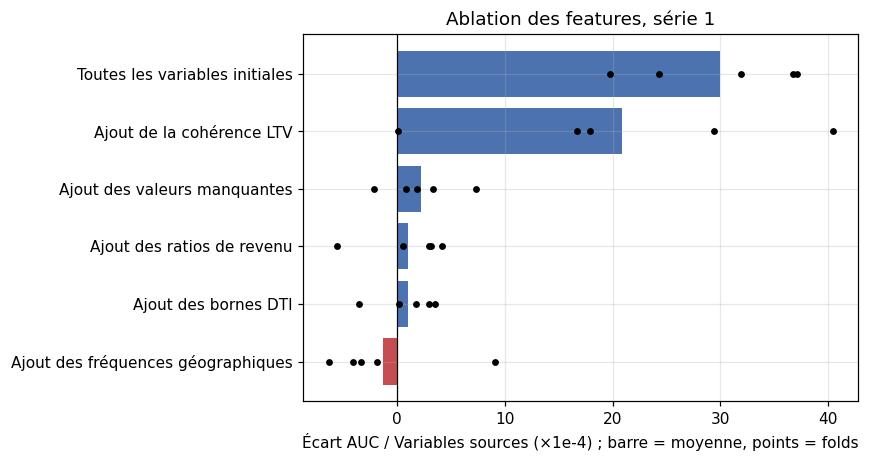

In [13]:
runs = load_runs(ARTIFACTS / '02_feature_engineering' / 'ablation_round1')
table, delta = paired_table(runs, 'variant', ABLATION_ORIGINAL, min_gain=0.0003)
table['feature_count'] = runs.groupby('variant')['feature_count'].first()
display_named(table.round(6))
plot_deltas(delta, ABLATION_ORIGINAL, 'Ablation des features, série 1')

Tous les blocs ensemble gagnent **0.0030, sur les 5 plis**. Presque tout vient du LTV recalculé : **+0.0021** à lui seul. Les autres blocs changent peu le score pris un par un, et les fréquences géographiques le font légèrement baisser.

### 6.2 Deuxième série (référence : tous les blocs de la première)

Même critère.

In [14]:
EXPERIMENT_ID = 'ablation_round2'
FOLDS = [1, 2, 3, 4, 5]
RUN_ONLY = None             # Exemple : [ABLATION_INITIAL_REFERENCE, ABLATION_ADD_LTV_PRECISION] ; None sélectionne toutes les variantes
OUTPUT_DIR = ARTIFACTS / '02_feature_engineering' / EXPERIMENT_ID

FAST_PARAMS = dict(
    iterations=1600, depth=8, learning_rate=0.05, l2_leaf_reg=3,
    bootstrap_type='Bernoulli', subsample=0.8,
    loss_function='Logloss', nan_mode='Min', random_seed=SEED,
    task_type='GPU', devices='0', thread_count=4,
    use_best_model=False, allow_writing_files=False, verbose=False,
)
INITIAL_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing', 'freq']     # Toutes les variables de la première série (Toutes les variables initiales)
CORE_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing']
VARIANTS = {
    ABLATION_INITIAL_REFERENCE: INITIAL_FEATURE_BLOCKS,
    ABLATION_ADD_LTV_PRECISION: INITIAL_FEATURE_BLOCKS + ['precision'],
    ABLATION_ADD_LTV_THRESHOLDS: INITIAL_FEATURE_BLOCKS + ['thresholds'],
    ABLATION_ADD_IMPLIED_VALUE: INITIAL_FEATURE_BLOCKS + ['implied'],
    ABLATION_ADD_TERM: INITIAL_FEATURE_BLOCKS + ['term'],
    ABLATION_ENRICHED_WITH_COUNTS: INITIAL_FEATURE_BLOCKS + ['precision', 'thresholds', 'implied', 'term'],
    # Après réglage, retirer les fréquences géographiques améliore légèrement CV et score public : tester la deuxième série sur cette base
    ABLATION_CORE_WITHOUT_COUNTS: CORE_FEATURE_BLOCKS,
    ABLATION_ENRICHED: CORE_FEATURE_BLOCKS + ['precision', 'thresholds', 'implied', 'term'],
}
if RUN_ONLY is not None:
    unknown = set(RUN_ONLY) - set(VARIANTS)
    if unknown:
        raise ValueError(f'Variantes inconnues dans RUN_ONLY : {sorted(unknown)}')

In [15]:
if TRAIN['ablation_round2']:
    ensure_catboost()
    ensure_gpu()
    fixed_config(OUTPUT_DIR, {
        'purpose': PURPOSE_ABLATION,
        'seed': SEED,
        'fast_params': {k: v for k, v in FAST_PARAMS.items() if k != 'thread_count'},
        'data_hashes': DATA_HASHES,
    })

    selected = {n: b for n, b in VARIANTS.items() if RUN_ONLY is None or n in RUN_ONLY}
    for fold in FOLDS:
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        for name, blocks in selected.items():
            result_path = OUTPUT_DIR / f'{name}__fold{fold}.json'
            if result_path.is_file():
                saved = json.loads(result_path.read_text(encoding='utf-8'))
                require(saved['blocks'] == blocks, f'{name} : définition modifiée ; renommer la variante')
                print(f'{name} fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
                continue
            train, _, cats = variant_frames(blocks)
            started = time.perf_counter()
            model = catboost.CatBoostClassifier(**FAST_PARAMS)
            model.fit(train.iloc[fit_idx], y.iloc[fit_idx], cat_features=cats)
            require(int(model.tree_count_) == FAST_PARAMS['iterations'], 'Nombre d’itérations incorrect')
            probability = checked_probabilities(model, train.iloc[valid_idx])
            actual = y.iloc[valid_idx]
            pd.DataFrame({'id': train_ids.iloc[valid_idx].to_numpy(), 'accepted': actual.to_numpy(),
                          'prob': probability}).to_csv(
                OUTPUT_DIR / f'{name}__fold{fold}.csv', index=False, float_format='%.12f')
            result = {
                'variant': name, 'blocks': blocks, 'fold': fold,
                'feature_count': train.shape[1],
                'valid_auc': roc_auc_score(actual, probability),
                'valid_logloss': log_loss(actual, probability, labels=[0, 1]),
                'seconds': time.perf_counter() - started, 'gpu_name': GPU_NAME,
                'finished_at_utc': datetime.now(timezone.utc).isoformat(),
            }
            write_json(result_path, result)
            print(f'{name} fold {fold}: AUC={result["valid_auc"]:.6f}  '
                  f'{train.shape[1]} colonnes  {result["seconds"]/60:.1f} min', flush=True)
            del model, train
            gc.collect()

    results = pd.DataFrame([json.loads(p.read_text(encoding='utf-8'))
                            for p in sorted(OUTPUT_DIR.glob('*__fold*.json'))])
    require(not results.empty, 'Aucun résultat terminé')
    auc = results.pivot(index='fold', columns='variant', values='valid_auc')
    require(ABLATION_INITIAL_REFERENCE in auc.columns, 'Référence Référence : variables initiales manquante')
    delta = auc.sub(auc[ABLATION_INITIAL_REFERENCE], axis=0)
    table = pd.DataFrame({
        'folds_done': auc.notna().sum(),
        'mean_auc': auc.mean(),
        MEAN_GAIN_VS_INITIAL_FEATURES: delta.mean(),
        FOLDS_BETTER_THAN_INITIAL_FEATURES: (delta > 0).sum(),
        'mean_logloss': results.groupby('variant')['valid_logloss'].mean(),
        'feature_count': results.groupby('variant')['feature_count'].first(),
    })
    table['keep'] = ((table['folds_done'] == 5) & (table[MEAN_GAIN_VS_INITIAL_FEATURES] >= 0.0003)
                     & (table[FOLDS_BETTER_THAN_INITIAL_FEATURES] >= 4))
    table.loc[ABLATION_INITIAL_REFERENCE, 'keep'] = False
    table = table.sort_values(MEAN_GAIN_VS_INITIAL_FEATURES, ascending=False)
    table.to_csv(OUTPUT_DIR / 'summary.csv')
    display_named(table.round(6))
    display_named(delta.round(6))
else:
    print("Bloc désactivé (TRAIN['ablation_round2'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['ablation_round2'] = False) ; affichage des résultats enregistrés dans artifacts/.


,folds,mean_auc,delta_vs_base,folds_better,keep,feature_count
variant,,,,,,
Variables enrichies sans fréquences géographiques,5,0.919350,0.001253,5,True,72
Variables enrichies avec fréquences géographiques,5,0.919319,0.001222,5,True,75
Ajout de la précision LTV,5,0.918845,0.000748,4,True,69
Ajout des seuils LTV,5,0.918837,0.000740,5,True,70
Ajout des variables de durée,5,0.918343,0.000246,3,False,70
Variables initiales sans fréquences géographiques,5,0.918215,0.000119,4,False,65
Ajout de la valeur immobilière implicite,5,0.918201,0.000104,3,False,70
Référence : variables initiales,5,0.918097,0.000000,0,False,68


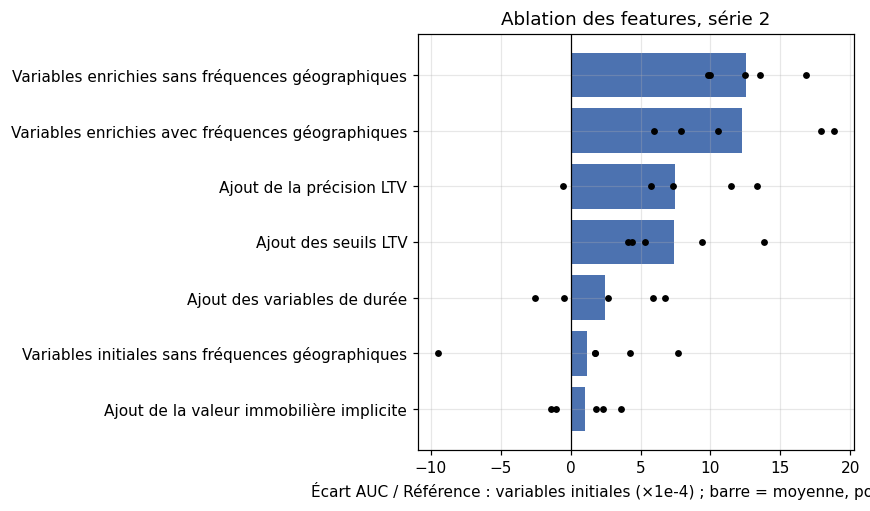

In [16]:
runs = load_runs(ARTIFACTS / '02_feature_engineering' / 'ablation_round2')
table, delta = paired_table(runs, 'variant', ABLATION_INITIAL_REFERENCE, min_gain=0.0003)
table['feature_count'] = runs.groupby('variant')['feature_count'].first()
display_named(table.round(6))
plot_deltas(delta, ABLATION_INITIAL_REFERENCE, 'Ablation des features, série 2')

Avec tous les blocs de la deuxième série et sans les fréquences géographiques (72 colonnes), le gain est de **0.00125, sur les 5 plis**. Pris seuls : précision du LTV +0.00075 (4 plis sur 5), seuils +0.00074 (5 sur 5). La valeur reconstituée et la durée ne passent pas le critère seules.

### 6.3 Troisième série (référence : les 72 colonnes)

Entre deux sessions Colab, le même modèle peut varier de quelques dix-millièmes. Le critère passe donc à 0.0005.

In [17]:
EXPERIMENT_ID = 'ablation_round3'
FOLDS = [1, 2, 3, 4, 5]
RUN_ONLY = None             # Exemple : [ABLATION_ENRICHED_REFERENCE, ABLATION_ADD_PRODUCT_FLAGS] ; None sélectionne toutes les variantes
OUTPUT_DIR = ARTIFACTS / '02_feature_engineering' / EXPERIMENT_ID

FAST_PARAMS = dict(
    iterations=1600, depth=8, learning_rate=0.05, l2_leaf_reg=3,
    bootstrap_type='Bernoulli', subsample=0.8,
    loss_function='Logloss', nan_mode='Min', random_seed=SEED,
    task_type='GPU', devices='0', thread_count=4,
    use_best_model=False, allow_writing_files=False, verbose=False,
)
CORE_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing']
ENRICHED_FEATURE_BLOCKS = CORE_FEATURE_BLOCKS + ['precision', 'thresholds', 'implied', 'term']   # Meilleur jeu de variables de la deuxième série (72 colonnes)
PRODUCT_RISK_BLOCKS = ['purpose', 'ltv_consistency', 'risk_layers', 'tract_income']
VARIANTS = {
    ABLATION_ENRICHED_REFERENCE: ENRICHED_FEATURE_BLOCKS,
    ABLATION_ADD_PRODUCT_FLAGS: ENRICHED_FEATURE_BLOCKS + ['purpose'],
    ABLATION_ADD_LTV_CONSISTENCY: ENRICHED_FEATURE_BLOCKS + ['ltv_consistency'],
    ABLATION_ADD_RISK_INTERACTIONS: ENRICHED_FEATURE_BLOCKS + ['risk_layers'],
    ABLATION_ADD_TRACT_INCOME: ENRICHED_FEATURE_BLOCKS + ['tract_income'],
    ABLATION_ALL_PRODUCT_RISK: ENRICHED_FEATURE_BLOCKS + PRODUCT_RISK_BLOCKS,
}
if RUN_ONLY is not None:
    unknown = set(RUN_ONLY) - set(VARIANTS)
    if unknown:
        raise ValueError(f'Variantes inconnues dans RUN_ONLY : {sorted(unknown)}')

In [18]:
if TRAIN['ablation_round3']:
    ensure_catboost()
    ensure_gpu()
    fixed_config(OUTPUT_DIR, {
        'purpose': PURPOSE_ABLATION,
        'seed': SEED,
        'fast_params': {k: v for k, v in FAST_PARAMS.items() if k != 'thread_count'},
        'data_hashes': DATA_HASHES,
    })

    selected = {n: b for n, b in VARIANTS.items() if RUN_ONLY is None or n in RUN_ONLY}
    for fold in FOLDS:
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        for name, blocks in selected.items():
            result_path = OUTPUT_DIR / f'{name}__fold{fold}.json'
            if result_path.is_file():
                saved = json.loads(result_path.read_text(encoding='utf-8'))
                require(saved['blocks'] == blocks, f'{name} : définition modifiée ; renommer la variante')
                print(f'{name} fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
                continue
            train, _, cats = variant_frames(blocks)
            started = time.perf_counter()
            model = catboost.CatBoostClassifier(**FAST_PARAMS)
            model.fit(train.iloc[fit_idx], y.iloc[fit_idx], cat_features=cats)
            require(int(model.tree_count_) == FAST_PARAMS['iterations'], 'Nombre d’itérations incorrect')
            probability = checked_probabilities(model, train.iloc[valid_idx])
            actual = y.iloc[valid_idx]
            pd.DataFrame({'id': train_ids.iloc[valid_idx].to_numpy(), 'accepted': actual.to_numpy(),
                          'prob': probability}).to_csv(
                OUTPUT_DIR / f'{name}__fold{fold}.csv', index=False, float_format='%.12f')
            result = {
                'variant': name, 'blocks': blocks, 'fold': fold,
                'feature_count': train.shape[1],
                'valid_auc': roc_auc_score(actual, probability),
                'valid_logloss': log_loss(actual, probability, labels=[0, 1]),
                'seconds': time.perf_counter() - started, 'gpu_name': GPU_NAME,
                'finished_at_utc': datetime.now(timezone.utc).isoformat(),
            }
            write_json(result_path, result)
            print(f'{name} fold {fold}: AUC={result["valid_auc"]:.6f}  '
                  f'{train.shape[1]} colonnes  {result["seconds"]/60:.1f} min', flush=True)
            del model, train
            gc.collect()

    results = pd.DataFrame([json.loads(p.read_text(encoding='utf-8'))
                            for p in sorted(OUTPUT_DIR.glob('*__fold*.json'))])
    require(not results.empty, 'Aucun résultat terminé')
    auc = results.pivot(index='fold', columns='variant', values='valid_auc')
    require(ABLATION_ENRICHED_REFERENCE in auc.columns, 'Référence Référence : variables enrichies manquante')
    delta = auc.sub(auc[ABLATION_ENRICHED_REFERENCE], axis=0)
    table = pd.DataFrame({
        'folds_done': auc.notna().sum(),
        'mean_auc': auc.mean(),
        MEAN_GAIN_VS_ENRICHED_FEATURES: delta.mean(),
        FOLDS_BETTER_THAN_ENRICHED_FEATURES: (delta > 0).sum(),
        'mean_logloss': results.groupby('variant')['valid_logloss'].mean(),
        'feature_count': results.groupby('variant')['feature_count'].first(),
    })
    table['keep'] = ((table['folds_done'] == 5) & (table[MEAN_GAIN_VS_ENRICHED_FEATURES] >= 0.0005)
                     & (table[FOLDS_BETTER_THAN_ENRICHED_FEATURES] >= 4))
    table.loc[ABLATION_ENRICHED_REFERENCE, 'keep'] = False
    table = table.sort_values(MEAN_GAIN_VS_ENRICHED_FEATURES, ascending=False)
    table.to_csv(OUTPUT_DIR / 'summary.csv')
    display_named(table.round(6))
    display_named(delta.round(6))
else:
    print("Bloc désactivé (TRAIN['ablation_round3'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['ablation_round3'] = False) ; affichage des résultats enregistrés dans artifacts/.


,folds,mean_auc,delta_vs_base,folds_better,keep,feature_count
variant,,,,,,
Ajout de tous les blocs produit et risque,5,0.919633,0.000350,3,False,78
Ajout de la cohérence des intervalles LTV,5,0.919604,0.000321,4,False,74
Ajout des indicateurs de produit,5,0.919583,0.000300,4,False,73
Ajout des interactions de risque,5,0.919557,0.000274,2,False,74
Ajout du revenu relatif au secteur,5,0.919372,0.000089,3,False,73
Référence : variables enrichies,5,0.919283,0.000000,0,False,72


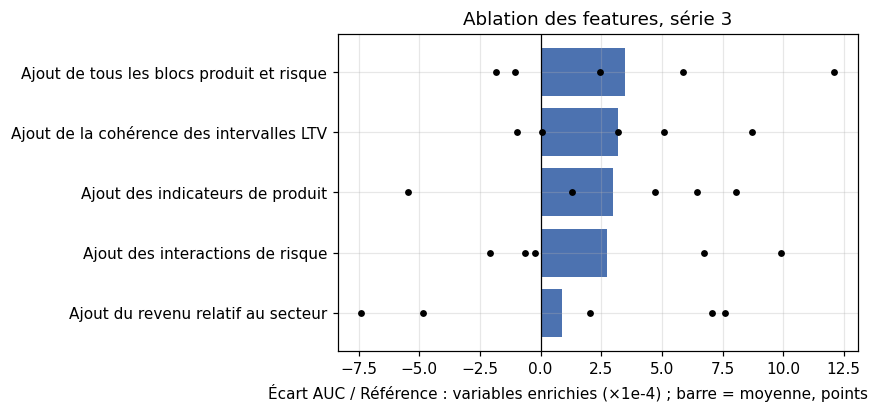

In [19]:
runs = load_runs(ARTIFACTS / '02_feature_engineering' / 'ablation_round3')
table, delta = paired_table(runs, 'variant', ABLATION_ENRICHED_REFERENCE, min_gain=0.0005)
table['feature_count'] = runs.groupby('variant')['feature_count'].first()
display_named(table.round(6))
plot_deltas(delta, ABLATION_ENRICHED_REFERENCE, 'Ablation des features, série 3')

Le meilleur candidat gagne 0.00035 sur 3 plis seulement. Aucun bloc ne passe le critère : on n'ajoute rien.

## 7. Jeux de variables gardés

| Jeu | Contenu | Colonnes | Utilisé par |
|---|---|---:|---|
| **enrichi** | 56 d'origine + `dti`, `ltv`, `income`, `missing`, `precision`, `thresholds`, `implied`, `term` | 72 | CatBoost profondeur 6 et profondeur 8 |
| **réduit** | le même sans `implied` ni `term` | 68 | CatBoost profondeur 6 |
| série 1 | 56 d'origine + tous les blocs de la première série | 68 | référence |

Le jeu réduit enlève seulement les variables *ajoutées* sur la durée ; la colonne d'origine `loan_term` est toujours là.